# MODEL: ResNet50
TASK : Crop Pest and Disease Detection - End-to-End Pipeline
Paste each CELL block into a separate cell in your Jupyter Notebook.
Run cells in order from top to bottom.

---


### Digital Image Processing Concepts Used in This Model

In digital image processing (DIP) applied to plant pathology, diagnosing crop pests and diseases requires analyzing multi-scale spatial textures, color channel variations, and morphological boundaries in leaf imagery. Pathological indicators—such as necrotic leaf spot margins, bacterial blights, and viral streak patterns—create localized high-frequency spatial gradients against healthy foliage.

#### Why Crop Images Require Preprocessing
1. **Uncontrolled Outdoor Lighting:** Natural field illumination introduces solar glare, deep shadows, and color temperature shifts that distort raw pixel intensity distributions.
2. **Variable Capture Perspective:** Handheld and drone cameras capture leaves at diverse angles and distances, altering apparent symptom dimensions and orientation.
3. **Complex Agricultural Backgrounds:** Soil, dead organic mulch, and background foliage introduce non-target high-frequency spatial noise.
4. **Sensor Downsampling & Quantization:** Converting optical signals into digital matrices requires standardized spatial and radiometric normalization.

#### Spatial and Intensity Transformations in Training
- **Geometric Transformations:** Horizontal and vertical reflections, affine rotations ($\pm 90^\circ$), and zoom scaling enforce rotational and scale invariance.
- **Intensity Transformations:** Contrast stretching and brightness adjustments simulate varying daylight intensity without altering structural lesion morphology.

#### ResNet50: Deep Feature Extraction via Residual Connections
Standard deep convolutional networks suffer from the **vanishing gradient problem**, where spatial gradient signals attenuate as they backpropagate through dozens of layers. ResNet50 resolves this using **identity skip connections**:
$$H(x) = F(x) + x$$
Where $F(x)$ represents the residual mapping learned by stacked convolutional layers, and $x$ is the unperturbed identity input. This architecture allows gradients to flow directly through 50 layers, enabling the extraction of deeply abstract, hierarchical disease representations that capture both fine local lesion margins and broad contextual leaf structures.

#### End-to-End DIP & Classification Pipeline
$$\text{Input Image } (H \times W \times 3) \longrightarrow \text{Image Decoding \& Resizing } (224 \times 224) \longrightarrow \text{Data Augmentation } \longrightarrow \text{ResNet Preprocessing (BGR + Mean Subtraction)} \longrightarrow \text{Deep Residual Feature Extraction } \longrightarrow \text{Global Pooling } \longrightarrow \text{Dense Classification}$$

> **Important Case Study Note:** This model performs **whole-image classification** (predicting the disease category for the entire tile) rather than explicit **semantic pixel segmentation** (which would delineate exact boundary contours for each diseased lesion).

### CELL 1 ── Install Dependencies


In [1]:
!pip install -q kagglehub split-folders numpy pandas scipy matplotlib seaborn scikit-learn tensorflow keras opencv-python pillow h5py tqdm requests

### CELL 2 ── Imports


In [2]:
import os
import warnings
import kagglehub
import splitfolders
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, callbacks
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### CELL 3 ── Verify & Load Local Dataset  (70 / 15 / 15)


In [3]:
SPLIT_DIR = "Dataset_Split"

if not os.path.exists(SPLIT_DIR):
    raw_path = "dataset" if os.path.exists("dataset") else kagglehub.dataset_download("nirmalsankalana/crop-pest-and-disease-detection")
    print("Source dataset at:", raw_path)
    print("Splitting (70/15/15) … this may take a moment.")
    splitfolders.ratio(raw_path, output=SPLIT_DIR, seed=42, ratio=(0.70, 0.15, 0.15), group_prefix=None)
    print("Split complete.")
else:
    print("Dataset_Split already ready — skipping split step.")

# Remove truncated/corrupted JPEGs that trigger decode_image/DecodeImage InvalidArgumentError
print("Verifying and cleaning damaged images...")
corrupt_count = 0
for root, _, files in os.walk(SPLIT_DIR):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            file_path = os.path.join(root, file)
            try:
                with open(file_path, "rb") as f:
                    _ = tf.io.decode_image(f.read(), expand_animations=False)
            except Exception:
                corrupt_count += 1
                os.remove(file_path)
if corrupt_count > 0:
    print(f"Removed {corrupt_count} damaged/unreadable images.")
else:
    print("All images verified clean.")

TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
VAL_DIR   = os.path.join(SPLIT_DIR, "val")
TEST_DIR  = os.path.join(SPLIT_DIR, "test")

print(f"  --> Train path : {TRAIN_DIR}")
print(f"  --> Val path   : {VAL_DIR}")
print(f"  --> Test path  : {TEST_DIR}")


100%|██████████| 1.25G/1.25G [01:07<00:00, 19.9MB/s]

Extracting files...


Source dataset at: /root/.cache/kagglehub/datasets/nirmalsankalana/crop-pest-and-disease-detection/versions/1
Splitting (70/15/15) … this may take a moment.


Copying files: 25220 files [00:06, 4135.80 files/s]


Split complete.
Verifying and cleaning damaged images...
Removed 96 damaged/unreadable images.
  --> Train path : Dataset_Split/train
  --> Val path   : Dataset_Split/val
  --> Test path  : Dataset_Split/test


### DIP: Digital Image Representation, Decoding, and Spatial Resizing

#### Digital Color Image Representation
A digital color photograph is represented as a 3D numerical matrix of shape $(H \times W \times 3)$, where $H$ is the spatial height, $W$ is the spatial width, and 3 represents the primary color channels: **Red (R), Green (G), and Blue (B)**. Each pixel intensity is an 8-bit unsigned integer ($uint8$) with values spanning $[0, 255]$.

#### Image Decoding
Stored JPEG images are compressed using Discrete Cosine Transform (DCT) quantization. During input pipeline execution, TensorFlow decompresses raw binary bitstreams into uncompressed 3D arrays of numerical pixel intensities.

#### Image Resizing and Spatial Downsampling
Deep neural networks process data in batches, requiring fixed, standardized tensor dimensions ($B \times H \times W \times C$):
- **ResNet50 Input Resolution:** All input images are standardized to **$224 \times 224$ pixels**.
- **Computational Trade-Off:** Resizing standardizes camera captures of varying resolutions into $224 \times 224 \times 3 = 150,528$ values, balancing computational throughput with structural fidelity.
- **Resolution Loss:** Downsampling high-resolution images can blur subtle early-stage fungal pustules or faint leaf miner tracks.
- **Aspect Ratio Distortion:** Direct bilinear downsampling to a square without padding may stretch non-square camera frames.

### CELL 4 ── Hyper-parameters & Data Loaders


In [4]:
BATCH_SIZE = 32
IMG_SIZE   = (224, 224)
EPOCHS     = 25
SEED       = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, seed=SEED, image_size=IMG_SIZE,
    batch_size=BATCH_SIZE, shuffle=False)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 17568 files belonging to 22 classes.
Found 3761 files belonging to 22 classes.
Found 3795 files belonging to 22 classes.
Classes (22): ['Cashew anthracnose', 'Cashew gumosis', 'Cashew healthy', 'Cashew leaf miner', 'Cashew red rust', 'Cassava bacterial blight', 'Cassava brown spot', 'Cassava green mite', 'Cassava healthy', 'Cassava mosaic', 'Maize fall armyworm', 'Maize grasshoper', 'Maize healthy', 'Maize leaf beetle', 'Maize leaf blight', 'Maize leaf spot', 'Maize streak virus', 'Tomato healthy', 'Tomato leaf blight', 'Tomato leaf curl', 'Tomato septoria leaf spot', 'Tomato verticulium wilt']


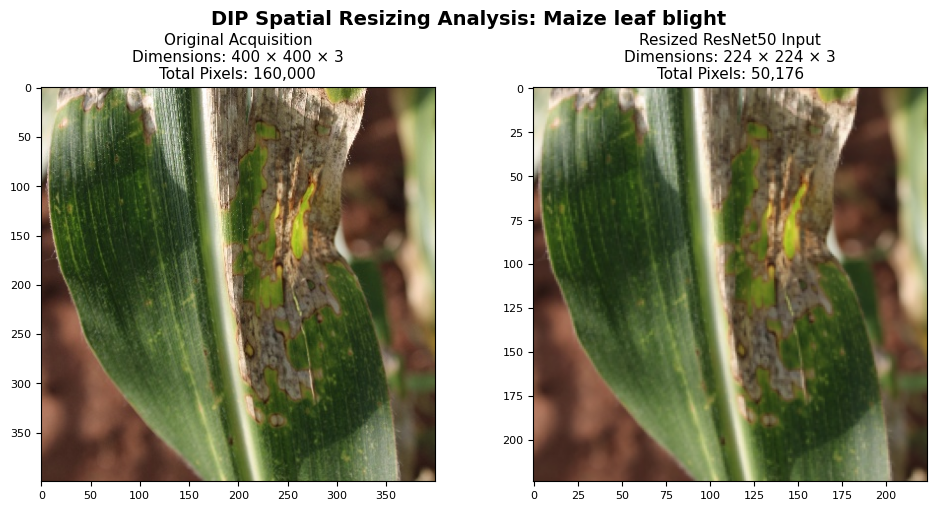

Spatial reduction ratio: 3.19x fewer pixels.


In [5]:
# DIP VISUALIZATION: Original Image vs. Resized Model Input (224x224)
import glob
from PIL import Image

sample_search = glob.glob(os.path.join(TRAIN_DIR, "*", "*.jpg"))
if sample_search:
    sample_file_path = sample_search[0]
    class_folder_name = os.path.basename(os.path.dirname(sample_file_path))

    orig_img = Image.open(sample_file_path)
    orig_w, orig_h = orig_img.size
    resized_img = orig_img.resize(IMG_SIZE, Image.BILINEAR)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle(f"DIP Spatial Resizing Analysis: {class_folder_name}", fontsize=14, fontweight="bold")

    axes[0].imshow(orig_img)
    axes[0].set_title(f"Original Acquisition\nDimensions: {orig_h} × {orig_w} × 3\nTotal Pixels: {orig_h * orig_w:,}", fontsize=11)
    axes[0].axis("on"); axes[0].tick_params(labelsize=8)

    axes[1].imshow(resized_img)
    axes[1].set_title(f"Resized ResNet50 Input\nDimensions: {IMG_SIZE[1]} × {IMG_SIZE[0]} × 3\nTotal Pixels: {IMG_SIZE[0] * IMG_SIZE[1]:,}", fontsize=11)
    axes[1].axis("on"); axes[1].tick_params(labelsize=8)

    plt.tight_layout()
    plt.show()
    print(f"Spatial reduction ratio: {(orig_h * orig_w) / (IMG_SIZE[0] * IMG_SIZE[1]):.2f}x fewer pixels.")
else:
    print("No images found for resizing demonstration.")

### CELL 5 ── Explore: Sample Images


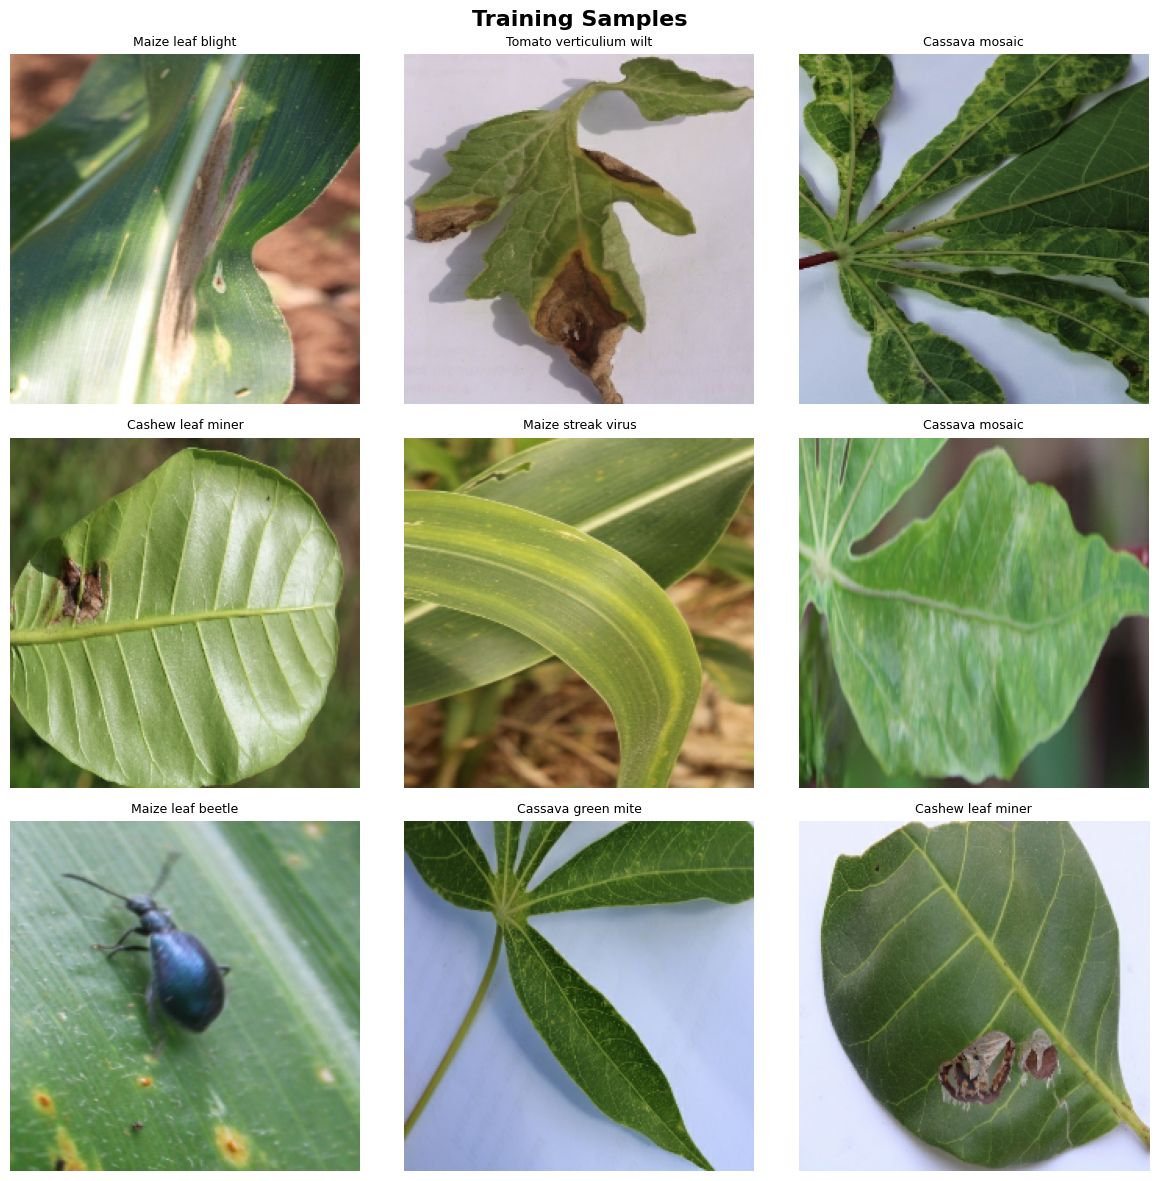

In [6]:
plt.figure(figsize=(12, 12))
plt.suptitle("Training Samples", fontsize=16, fontweight="bold")
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[labels[i]], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

### CELL 6 ── Class Distribution


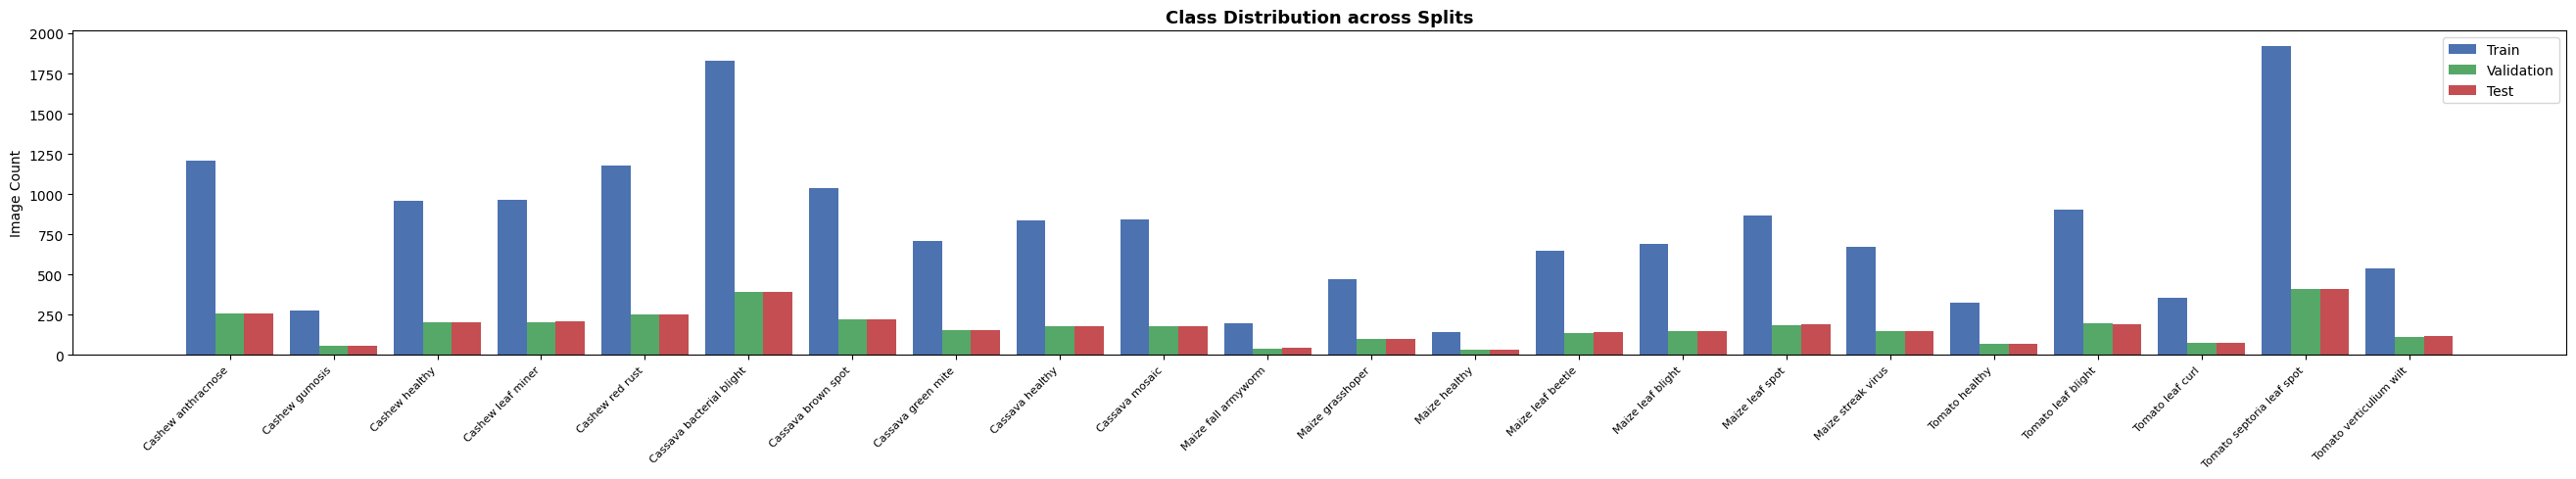

In [7]:
def count_classes(directory, class_names):
    return [len(os.listdir(os.path.join(directory, c))) for c in class_names]

train_counts = count_classes(TRAIN_DIR, CLASS_NAMES)
val_counts   = count_classes(VAL_DIR,   CLASS_NAMES)
test_counts  = count_classes(TEST_DIR,  CLASS_NAMES)

x = np.arange(NUM_CLASSES)
w = 0.28
fig, ax = plt.subplots(figsize=(max(12, NUM_CLASSES * 1.2), 5))
ax.bar(x - w, train_counts, w, label="Train",      color="#4C72B0")
ax.bar(x,     val_counts,   w, label="Validation",  color="#55A868")
ax.bar(x + w, test_counts,  w, label="Test",        color="#C44E52")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8)
ax.set_title("Class Distribution across Splits", fontsize=13, fontweight="bold")
ax.set_ylabel("Image Count"); ax.legend()
plt.tight_layout(); plt.show()

### DIP: Geometric and Intensity Transformations

Data augmentation applies digital image processing transformations to synthetic training images, expanding effective dataset variance and enforcing invariance to camera orientation and field illumination.

#### 1. Geometric Transformations (Spatial Coordinate Remapping)
Geometric transformations alter the spatial coordinates $(x, y)$ of image pixels via 2D spatial mapping functions $I'(x', y') = I(T_x(x, y), T_y(x, y))$:
- **Spatial Reflection (Flipping):** `RandomFlip("horizontal_and_vertical")` reflects pixels across horizontal ($y' = H - y$) and vertical ($x' = W - x$) axes. Foliar diseases possess no fixed gravitational orientation.
- **Rotation:** `RandomRotation(0.25)` applies 2D affine rotation. In Keras, a factor of **$0.25$ represents a fraction of $2\pi$**, meaning images are randomly rotated within $[-0.25 \times 360^\circ, +0.25 \times 360^\circ] = [-90^\circ, +90^\circ]$ (a full quarter turn), **not** 25 degrees.
- **Scaling (Zoom):** `RandomZoom(0.20)` scales coordinates by $\pm 20\%$, simulating variable camera working distances.

#### 2. Intensity Transformations (Radiometric Point Operations)
Intensity transformations modify pixel intensity values directly without altering spatial pixel geometry:
- **Contrast Adjustment:** `RandomContrast(0.15)` dynamically stretches or compresses the image dynamic range around its mean intensity: $I'(x,y) = \bar{I} + c \cdot (I(x,y) - \bar{I})$, simulating variable ambient daylight and cloud cover.
- **Brightness Adjustment:** `RandomBrightness(0.10)` shifts intensity levels additively: $I'(x,y) = I(x,y) + \delta$, simulating overexposure or deep canopy shading.

### CELL 7 ── Data Augmentation


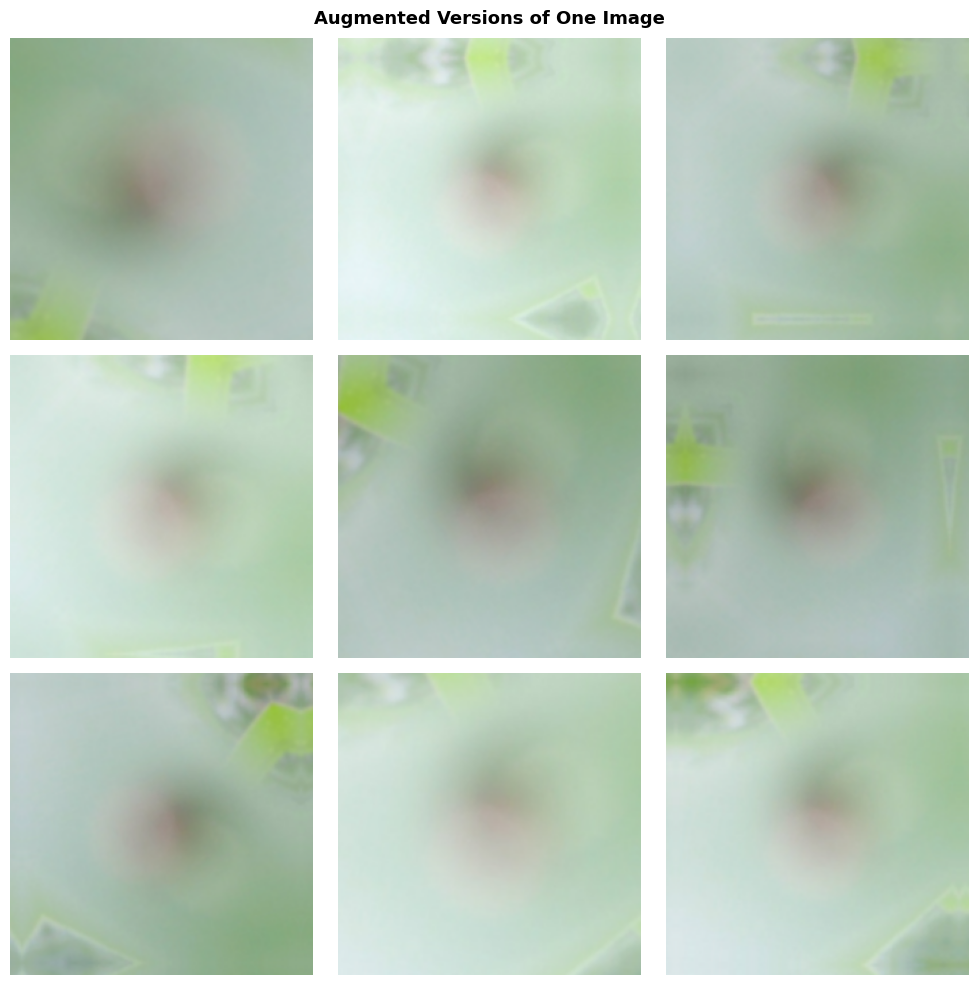

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.20),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10),
], name="augmentation")

for images, _ in train_ds.take(1):
    sample = images[0]
aug_samples = [data_augmentation(tf.expand_dims(sample, 0))[0] for _ in range(9)]

plt.figure(figsize=(10, 10))
plt.suptitle("Augmented Versions of One Image", fontsize=13, fontweight="bold")
for i, img in enumerate(aug_samples):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img.numpy().astype("uint8")); plt.axis("off")
plt.tight_layout(); plt.show()

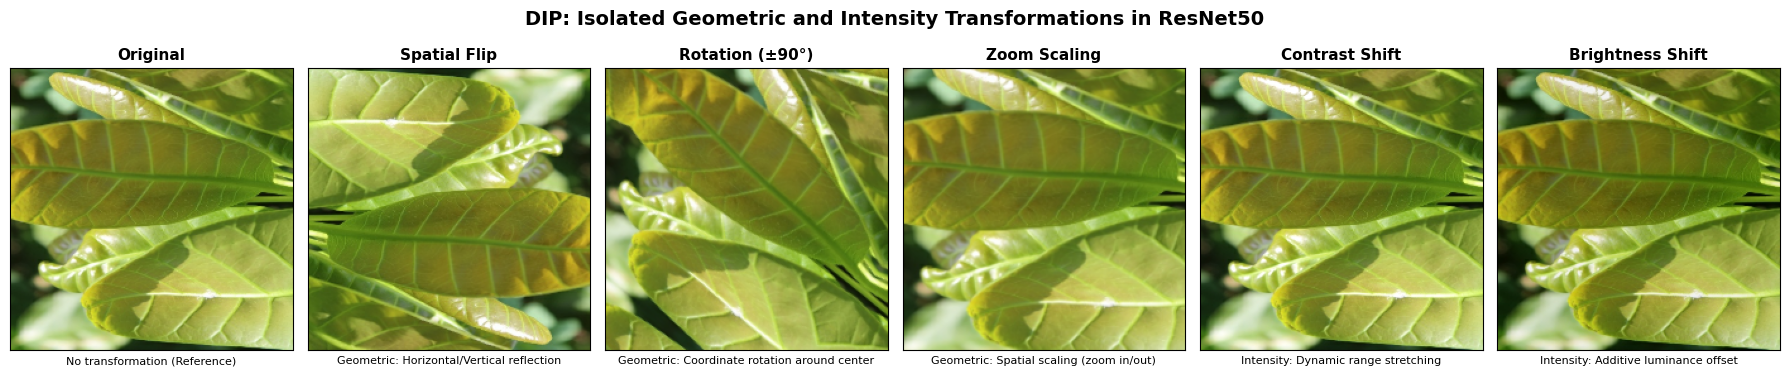

In [9]:
# DIP VISUALIZATION: Individual Geometric and Intensity Transformations Applied Separately
for images, _ in train_ds.take(1):
    base_sample = images[0]
    break

t_flip = layers.RandomFlip("horizontal_and_vertical", seed=42)
t_rot  = layers.RandomRotation(0.25, seed=42)            # +/- 90 degrees
t_zoom = layers.RandomZoom(0.20, seed=42)                # +/- 20% zoom
t_cont = layers.RandomContrast(0.15, seed=42)            # +/- 15% contrast
t_brit = layers.RandomBrightness(0.10, value_range=(0, 255), seed=42) # +/- 10% brightness

sample_tensor = tf.expand_dims(base_sample, 0)

transforms_list = [
    ("Original", base_sample.numpy().astype("uint8"), "No transformation (Reference)"),
    ("Spatial Flip", t_flip(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Horizontal/Vertical reflection"),
    ("Rotation (±90°)", t_rot(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Coordinate rotation around center"),
    ("Zoom Scaling", t_zoom(sample_tensor)[0].numpy().astype("uint8"), "Geometric: Spatial scaling (zoom in/out)"),
    ("Contrast Shift", t_cont(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Dynamic range stretching"),
    ("Brightness Shift", t_brit(sample_tensor)[0].numpy().astype("uint8"), "Intensity: Additive luminance offset"),
]

fig, axes = plt.subplots(1, 6, figsize=(18, 3.8))
fig.suptitle("DIP: Isolated Geometric and Intensity Transformations in ResNet50", fontsize=14, fontweight="bold")

for ax, (title, img_trans, desc) in zip(axes, transforms_list):
    ax.imshow(img_trans)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(desc, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

### DIP: Convolutional Filtering and Hierarchical Feature Extraction

#### Mathematical Formulation of 2D Spatial Convolution
In discrete 2D digital image processing, spatial filtering correlates an input feature map $X$ with a 2D filter kernel $K$ of spatial dimensions $M \times N$:

$$Y(i, j) = (X * K)(i, j) = \sum_{m=-M/2}^{M/2} \sum_{n=-N/2}^{N/2} K(m, n) \cdot X(i + m, j + n)$$

#### ResNet50: Deep Bottleneck Residual Architecture
ResNet50 implements a 50-layer hierarchical feature extractor organized into 5 stages using **Bottleneck Residual Blocks**:
1. **$1 \times 1$ Convolution (Projection):** Compresses channel dimensionality to reduce computational load.
2. **$3 \times 3$ Spatial Convolution:** Performs spatial filtering to capture oriented edges, color transitions, and lesion textures.
3. **$1 \times 1$ Convolution (Expansion):** Restores channel dimensionality back to high-capacity representation.
4. **Identity Shortcut Connection:**
   $$H(x) = \sigma(F(x, \{W_i\}) + x)$$
   Where $F(x)$ is the residual mapping and $x$ is the identity shortcut. This residual architecture preserves low-level spatial gradient information across deep feature hierarchies, preventing vanishing gradients.

#### Feature Hierarchy in Crop Pathology
- **Stages 1 & 2:** Capture low-level spatial primitives: sharp leaf edges, specular highlights, and primary vein contours.
- **Stage 3:** Isolates textural primitives: fungal spore clusters, chlorotic halos, and lesion boundaries.
- **Stages 4 & 5:** Synthesize complex pathological phenotypes: systemic viral mosaic patterns, severe bacterial blight spread, and leaf curl distortions.

---

### DIP: Pixel Intensity Preprocessing

| Model | Preprocessing Function | Expected Pixel Scale | Transformations Applied |
|---|---|---|---|
| **ResNet50** | `tf.keras.applications.resnet50.preprocess_input` | $[0, 255]$ raw uint8/float32 | 1. RGB $\to$ BGR channel permutation<br>2. ImageNet mean subtraction: $[-103.939, -116.779, -123.68]$ |

#### Preprocessing Mechanism:
Unlike models that rescale to $[0, 1]$ or $[-1, 1]$, ResNet50 retains raw dynamic magnitude while:
1. Reordering channels from RGB to **BGR** to match the legacy Caffe framework format.
2. Centering pixel intensities by subtracting the mean ImageNet channel vector:
   $$B' = B - 103.939, \quad G' = G - 116.779, \quad R' = R - 123.68$$
This centers data around the origin, improving gradient flow during convolutional optimization.

### CELL 8 ── Build ResNet50 Transfer Learning Model


In [10]:
base_model = ResNet50(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs  = tf.keras.Input(shape=IMG_SIZE + (3,))
x       = data_augmentation(inputs)
x       = layers.Lambda(lambda img: preprocess_input(img), name="resnet_preprocess")(x)          # ResNet50 expects BGR mean-subtracted
x       = base_model(x, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.BatchNormalization()(x)
x       = layers.Dropout(0.40)(x)
x       = layers.Dense(512, activation="relu",
                        kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x       = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="ResNet50_CropDisease")
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "ResNet50_CropDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess (Lambda)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │        11,286 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,656,278 (94.06 MB)

 Trainable params: 1,064,470 (4.06 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

### DIP: Visualizing Pretrained Convolutional Feature Maps

Below, we pass a sample test image through the pretrained ResNet50 backbone to inspect the activation feature maps produced by its very first convolutional layer (`conv1_conv`).

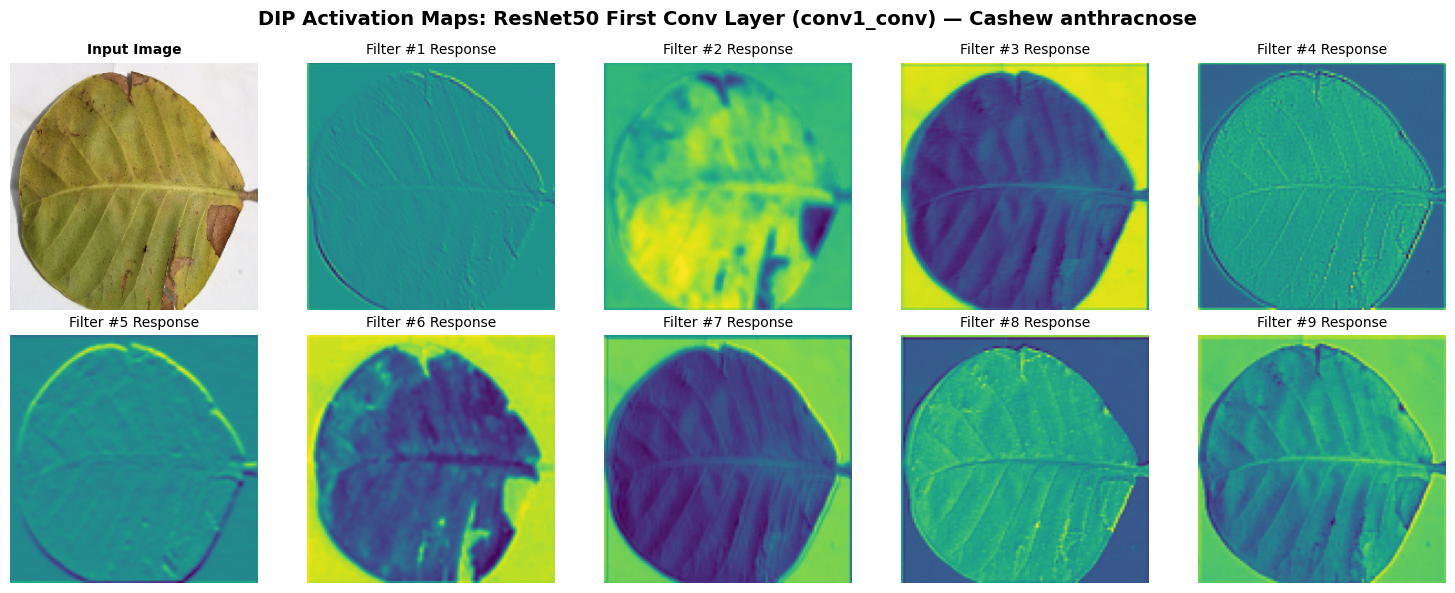

In [11]:
# DIP VISUALIZATION: Pretrained ResNet50 First Convolutional Layer Feature Maps
try:
    # Target the very first conv layer of ResNet50 (conv1_conv)
    first_conv_layer = base_model.get_layer("conv1_conv")
    feat_extractor = tf.keras.Model(inputs=base_model.input, outputs=first_conv_layer.output)

    for test_imgs, test_lbls in test_ds.take(1):
        sample_img = test_imgs[0:1] # shape (1, 224, 224, 3)
        sample_lbl = test_lbls[0].numpy()
        break

    # Preprocess image as ResNet expects (BGR + mean subtraction)
    preproc_sample = preprocess_input(tf.cast(sample_img, tf.float32))
    feat_maps = feat_extractor.predict(preproc_sample, verbose=0)
    # feat_maps shape: (1, 112, 112, 64)

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle(f"DIP Activation Maps: ResNet50 First Conv Layer (conv1_conv) — {CLASS_NAMES[sample_lbl]}", fontsize=14, fontweight="bold")

    axes[0, 0].imshow(sample_img[0].numpy().astype("uint8"))
    axes[0, 0].set_title("Input Image", fontsize=10, fontweight="bold")
    axes[0, 0].axis("off")

    for idx in range(1, 10):
        r, c = divmod(idx, 5)
        fmap = feat_maps[0, :, :, idx - 1]
        axes[r, c].imshow(fmap, cmap="viridis")
        axes[r, c].set_title(f"Filter #{idx} Response", fontsize=10)
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Feature map visualization skipped: {e}")

### Digital Image Processing vs. Machine Learning in Model Training

- **Image Processing Operations:** Resizing to $224 \times 224$, geometric coordinate transforms (flips, rotations, zooms), RGB to BGR channel reordering, ImageNet mean centering, 2D bottleneck spatial convolutions, and global average pooling.
- **Machine Learning Operations:** Categorical cross-entropy loss computation, error backpropagation, Adam optimizer weight updates, learning rate reduction on plateaus, transfer learning backbone freezing (Phase 1), and selective layer unfreezing (Phase 2 fine-tuning).

DIP structures the optical signals into informative spatial feature representations; ML discovers the optimal weighting parameters across those representations.

### CELL 9 ── Compile & Train Phase 1 (frozen backbone)


In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cb_early = callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                   restore_best_weights=False, verbose=1)
cb_lr    = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.4,
                                       patience=2, min_lr=1e-7, verbose=1)
cb_ckpt  = callbacks.ModelCheckpoint("best_resnet50.keras", save_best_only=True,
                                      monitor="val_accuracy", verbose=1)

history = model.fit(
    train_ds, epochs=EPOCHS, validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt], verbose=1)
print("Phase-1 training complete.")

Epoch 1/25
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5966 - loss: 1.6200
Epoch 1: val_accuracy improved from None to 0.77931, saving model to best_resnet50.keras

Epoch 1: finished saving model to best_resnet50.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 112s 187ms/step - accuracy: 0.6656 - loss: 1.3231 - val_accuracy: 0.7793 - val_loss: 0.8160 - learning_rate: 0.0010
Epoch 2/25
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.7395 - loss: 0.9661
Epoch 2: val_accuracy improved from 0.77931 to 0.80617, saving model to best_resnet50.keras

Epoch 2: finished saving model to best_resnet50.keras
549/549 ━━━━━━━━━━━━━━━━━━━━ 103s 188ms/step - accuracy: 0.7428 - loss: 0.9407 - val_accuracy: 0.8062 - val_loss: 0.7391 - learning_rate: 0.0010
Epoch 3/25
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.7546 - loss: 0.8503
Epoch 3: val_accuracy did not improve from 0.80617
549/549 ━━━━━━━━━━━━━━━━━━━━ 142s 188ms/step - accuracy: 0.7536 - loss: 0.8524 - val_accuracy: 0.8048 - 

### CELL 10 ── Fine-Tuning Phase 2 (unfreeze last 20 layers)


In [13]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_ft = model.fit(
    train_ds, epochs=10, validation_data=val_ds,
    callbacks=[cb_early, cb_lr, cb_ckpt], verbose=1)
print("Fine-tuning complete.")

for k in history.history:
    history.history[k] += history_ft.history.get(k, [])

Epoch 1/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.8533 - loss: 0.5795
Epoch 1: val_accuracy did not improve from 0.86785
549/549 ━━━━━━━━━━━━━━━━━━━━ 133s 224ms/step - accuracy: 0.8592 - loss: 0.5628 - val_accuracy: 0.8612 - val_loss: 0.5478 - learning_rate: 1.0000e-05
Epoch 2/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.8605 - loss: 0.5500
Epoch 2: ReduceLROnPlateau reducing learning rate to 3.999999898951501e-06.

Epoch 2: val_accuracy did not improve from 0.86785
549/549 ━━━━━━━━━━━━━━━━━━━━ 118s 215ms/step - accuracy: 0.8658 - loss: 0.5402 - val_accuracy: 0.8657 - val_loss: 0.5387 - learning_rate: 1.0000e-05
Epoch 3/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.8642 - loss: 0.5417
Epoch 3: val_accuracy did not improve from 0.86785
549/549 ━━━━━━━━━━━━━━━━━━━━ 121s 220ms/step - accuracy: 0.8674 - loss: 0.5281 - val_accuracy: 0.8636 - val_loss: 0.5371 - learning_rate: 4.0000e-06
Epoch 4/10
549/549 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - acc

### CELL 11 ── Training Curves


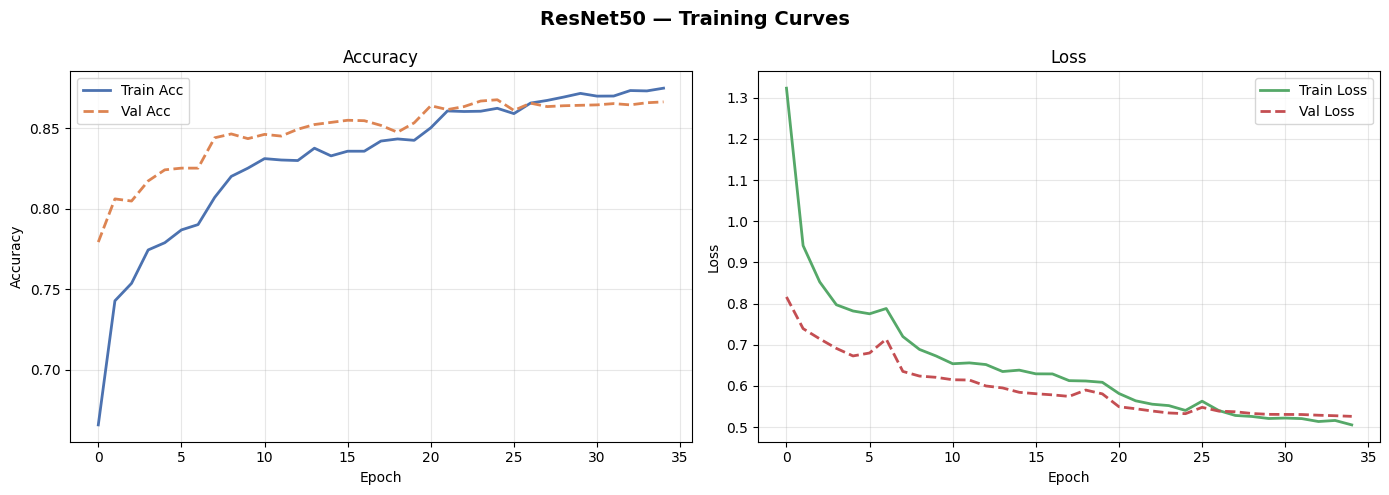

In [14]:
acc     = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss    = history.history["loss"]
val_loss= history.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("ResNet50 — Training Curves", fontsize=14, fontweight="bold")

axes[0].plot(acc,     label="Train Acc",  linewidth=2, color="#4C72B0")
axes[0].plot(val_acc, label="Val Acc",    linewidth=2, color="#DD8452", linestyle="--")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(loss,     label="Train Loss", linewidth=2, color="#55A868")
axes[1].plot(val_loss, label="Val Loss",   linewidth=2, color="#C44E52", linestyle="--")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

### CELL 12 ── Evaluate on Test Set


In [15]:
model.load_weights("best_resnet50.keras")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy : {test_acc  * 100:.2f}%")
print(f"Test Loss     : {test_loss:.4f}")

119/119 ━━━━━━━━━━━━━━━━━━━━ 17s 146ms/step - accuracy: 0.8735 - loss: 0.5460

Test Accuracy : 87.35%
Test Loss     : 0.5460


### CELL 13 ── Confusion Matrix & Classification Report



Classification Report:
                           precision    recall  f1-score   support

       Cashew anthracnose     0.9383    0.8769    0.9066       260
           Cashew gumosis     1.0000    1.0000    1.0000        60
           Cashew healthy     0.9309    0.9806    0.9551       206
        Cashew leaf miner     0.9360    0.9135    0.9246       208
          Cashew red rust     0.9767    0.9921    0.9843       253
 Cassava bacterial blight     0.8641    0.9542    0.9069       393
       Cassava brown spot     0.9128    0.8924    0.9025       223
       Cassava green mite     0.9209    0.8366    0.8767       153
          Cassava healthy     0.9465    0.9833    0.9646       180
           Cassava mosaic     0.9939    0.8956    0.9422       182
      Maize fall armyworm     0.9744    0.8636    0.9157        44
         Maize grasshoper     0.9519    0.9706    0.9612       102
            Maize healthy     0.7111    1.0000    0.8312        32
        Maize leaf beetle     0.9720 

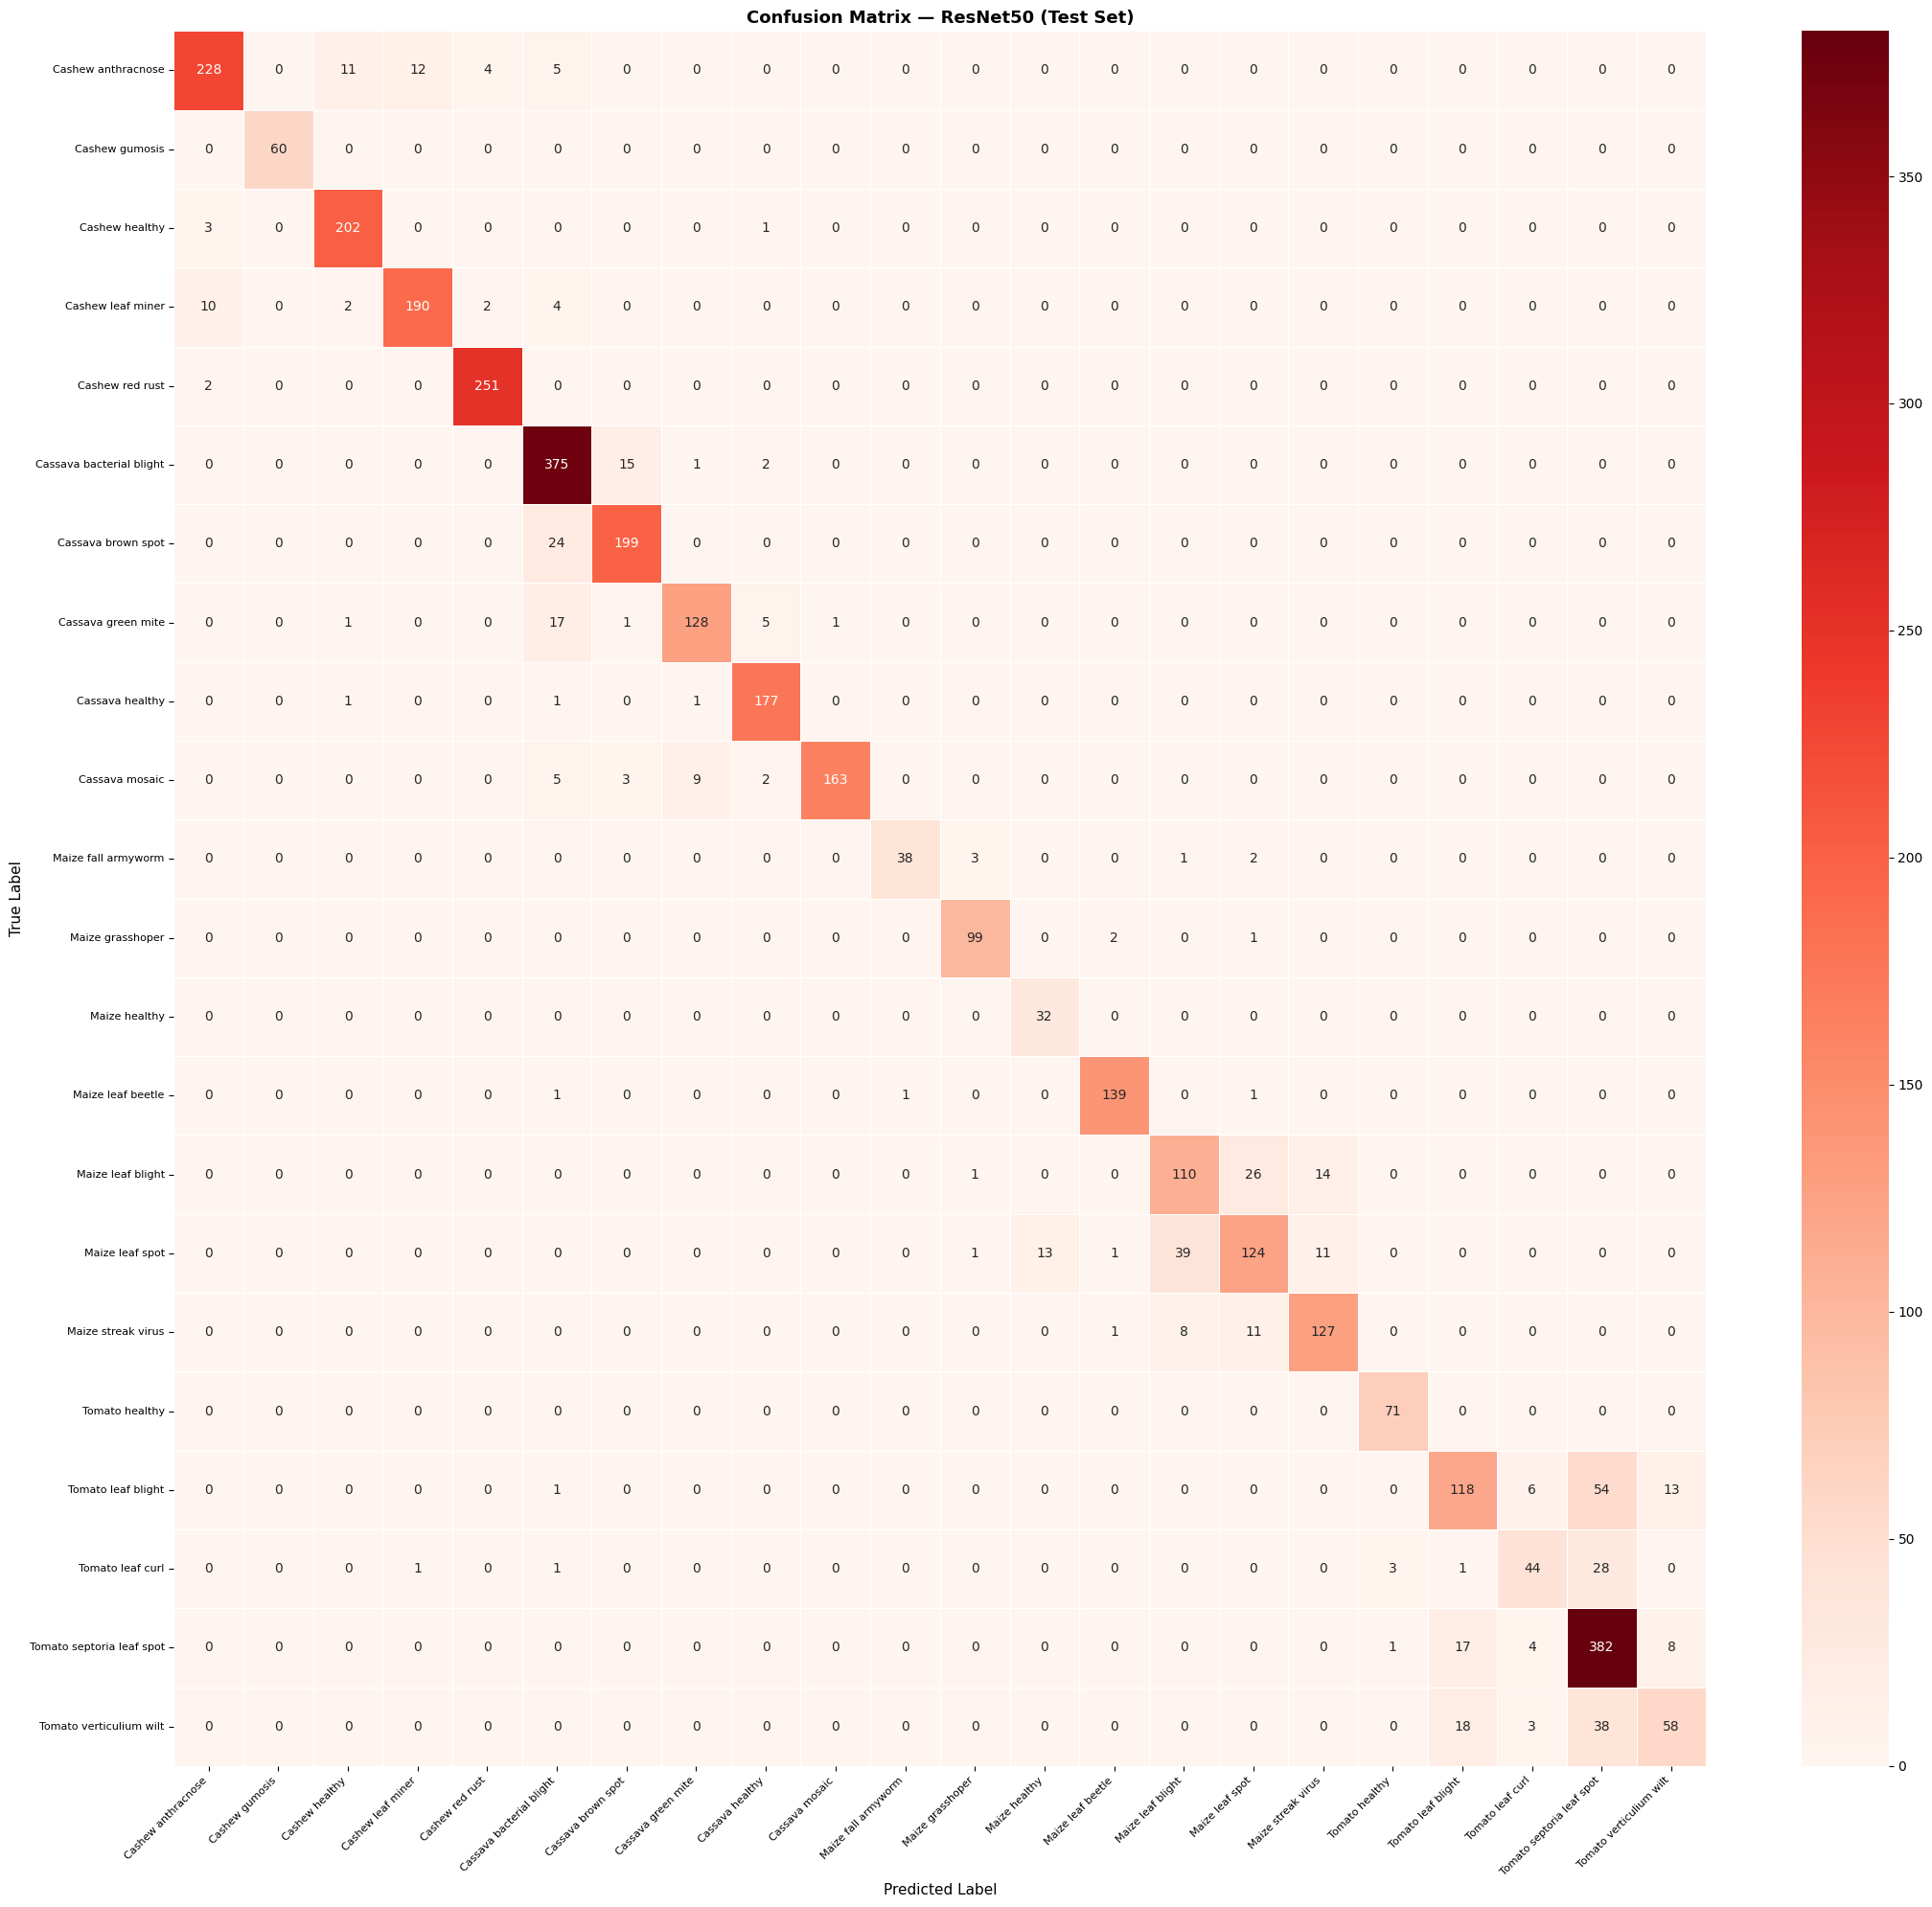

In [16]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(12, NUM_CLASSES), max(10, NUM_CLASSES - 2)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
plt.title("Confusion Matrix — ResNet50 (Test Set)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=11); plt.ylabel("True Label", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=8); plt.yticks(fontsize=8)
plt.tight_layout(); plt.show()

### CELL 14 ── Per-Class Accuracy Bar Chart


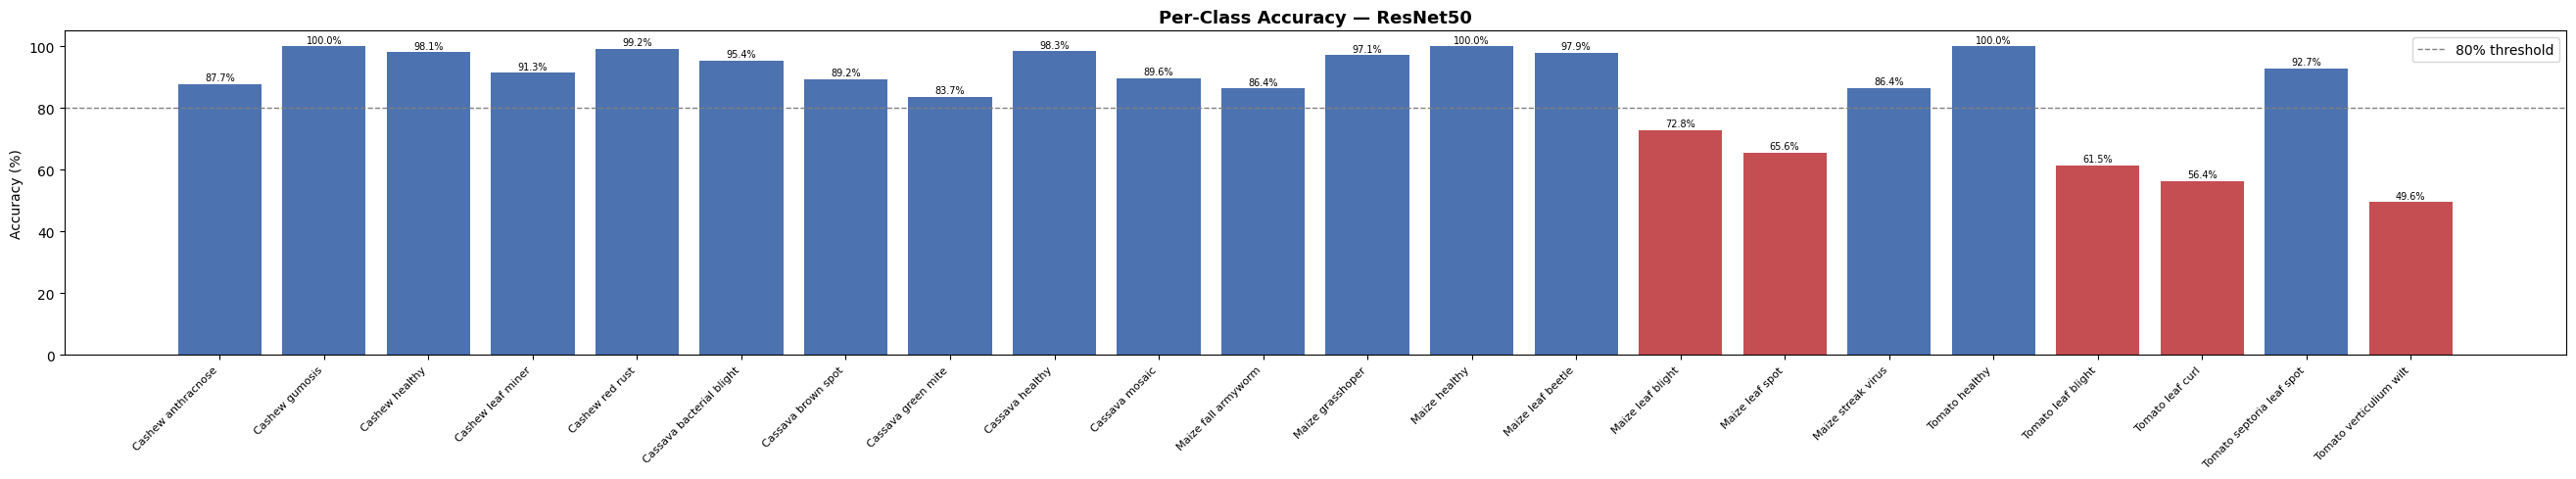

In [17]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(max(12, NUM_CLASSES * 1.2), 5))
colors = ["#4C72B0" if a >= 0.8 else "#C44E52" for a in per_class_acc]
bars = plt.bar(CLASS_NAMES, per_class_acc * 100, color=colors)
plt.axhline(y=80, color="grey", linestyle="--", linewidth=1, label="80% threshold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.ylabel("Accuracy (%)"); plt.title("Per-Class Accuracy — ResNet50", fontsize=13, fontweight="bold")
plt.legend()
for bar, acc_val in zip(bars, per_class_acc):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{acc_val*100:.1f}%", ha="center", va="bottom", fontsize=7)
plt.tight_layout(); plt.show()

### CELL 15 ── Sample Predictions Grid (Green = Correct, Red = Wrong)


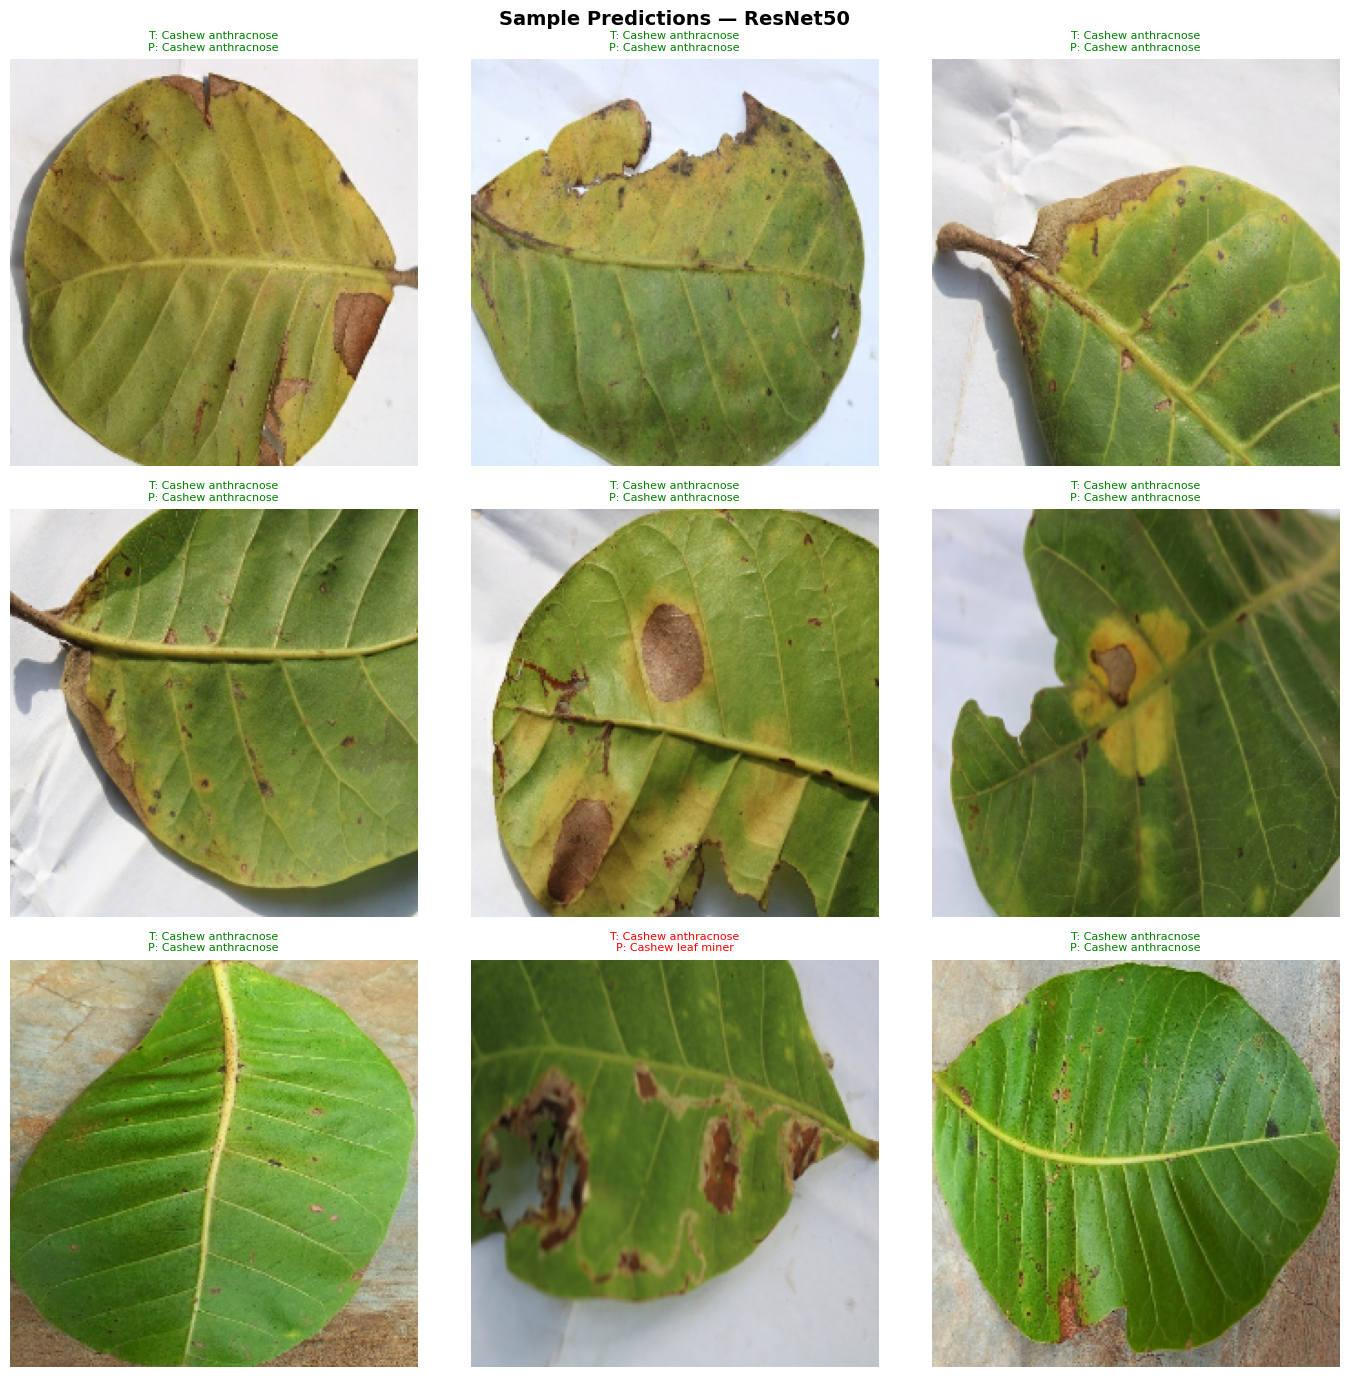

In [18]:
plt.figure(figsize=(14, 14))
plt.suptitle("Sample Predictions — ResNet50", fontsize=14, fontweight="bold")
for images, labels in test_ds.take(1):
    preds = np.argmax(model.predict(images, verbose=0), axis=1)
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_lbl = CLASS_NAMES[labels[i]]
        pred_lbl = CLASS_NAMES[preds[i]]
        colour   = "green" if true_lbl == pred_lbl else "red"
        plt.title(f"T: {true_lbl}\nP: {pred_lbl}", color=colour, fontsize=8)
        plt.axis("off")
plt.tight_layout(); plt.show()

### Interpretation of Image-Based Classification Results

In evaluating the sample prediction grid and confusion matrix from a digital image processing perspective:

1. **Visual Cues Leveraged by the Classifier:**
   - **Chromatic Discoloration:** Chlorotic margins and dark necrotic lesions serve as primary chromatic markers.
   - **Spatial Texture:** Powdery mildew, serpentine leaf miner tracks, and fungal spots provide distinct spatial frequency signatures.
2. **Sources of Inter-Class Confusion:**
   - **Morphological Similarity:** Early blight and leaf spots produce similar circular necrotic lesions.
   - **Environmental Artifacts:** Harsh daylight glares and deep foliage shadows can distort color and contrast.
   - **Complex Backgrounds:** Soil backgrounds and overlapping non-target vegetation introduce spurious edge responses.
3. **Academic Clarification on Evaluation vs. DIP:**
   - A **confusion matrix** evaluates categorical classification performance, not digital image processing.
   - A **whole-image classification label** indicates the diagnosis of the overall image tile; it does **not** generate pixel-level lesion boundary masks.
   - **Activation maps** show filter responses across spatial receptive fields; they do **not** constitute semantic segmentation masks.

### CELL 16 ── Save Final Model


In [19]:
model.save("ResNet50_Crop_Disease_Final.keras")
print("Model saved →  ResNet50_Crop_Disease_Final.keras")

Model saved →  ResNet50_Crop_Disease_Final.keras


### Digital Image Processing Summary and Case Study Findings

#### 1. Input Image Representation and Dimensions
ResNet50 processes standardized $224 \times 224 \times 3$ RGB digital images ($150,528$ pixel intensity values), decoded from JPEG files into numerical arrays.

#### 2. Image Transformations Applied
- **Geometric Transformations:** Horizontal and vertical reflections, affine rotation ($\pm 90^\circ$), and zoom scaling ($\pm 20\%$) enforce rotational and scale invariance against camera positioning.
- **Intensity Transformations:** Contrast adjustment ($\pm 15\%$) and brightness shifts ($\pm 10\%$) simulate changing sunlight and exposure levels.

#### 3. Pixel Intensity Preprocessing
Input tensors undergo channel permutation from RGB to BGR, followed by ImageNet channel mean subtraction ($[-103.939, -116.779, -123.68]$) via `resnet50.preprocess_input`.

#### 4. Convolutional Feature Extraction
ResNet50 employs a 50-layer deep bottleneck residual architecture. Identity shortcut connections preserve spatial gradient signals across deep hierarchies, enabling the network to learn rich, abstract pathological features without degradation.

#### 5. Relevance to Crop Disease Identification
The deep bottleneck architecture successfully extracts intricate visual features of foliar diseases, including irregular lesion contours, halo chlorosis, and textural disfigurations.

#### 6. Limitations of the Image Processing Approach
- **No Explicit Lesion Segmentation:** Categorizes whole image tiles rather than segmenting individual lesion perimeters.
- **Downsampling:** Bilinear downsampling to $224 \times 224$ can suppress very fine micro-lesions.
- **Background Interference:** In the absence of explicit background masking, complex soil and weed textures can influence predictions.